**LSTM for Sarcasm Text Classification**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

np.random.seed(42)
tf.random.set_seed(42)

Load the uploaded dataset

In [2]:
df = pd.read_json('Sarcasm_Headlines_Dataset.json', lines=True)
print('Shape:', df.shape)
display(df.head())
print(df.isnull().sum())
print(df['is_sarcastic'].value_counts())

Shape: (26709, 3)


,article_link,headline,is_sarcastic
0,https://www.huffingtonpost.com/entry/versace-b...,former versace store clerk sues over secret 'b...,0
1,https://www.huffingtonpost.com/entry/roseanne-...,the 'roseanne' revival catches up to our thorn...,0
2,https://local.theonion.com/mom-starting-to-fea...,mom starting to fear son's web series closest ...,1
3,https://politics.theonion.com/boehner-just-wan...,"boehner just wants wife to listen, not come up...",1
4,https://www.huffingtonpost.com/entry/jk-rowlin...,j.k. rowling wishes snape happy birthday in th...,0


article_link    0
headline        0
is_sarcastic    0
dtype: int64
is_sarcastic
0    14985
1    11724
Name: count, dtype: int64


Prepare text and target

In [3]:
df = df[['headline', 'is_sarcastic']].dropna().copy()
df['headline'] = df['headline'].astype(str)
X = df['headline']
y = df['is_sarcastic'].astype(int)
print('Class labels:', sorted(y.unique()))

Class labels: [np.int64(0), np.int64(1)]


Train/test split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', len(X_train), 'Test:', len(X_test))

Train: 21367 Test: 5342


Tokenization and padding (maxlen=50)

In [5]:
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)
train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)
X_train_pad = pad_sequences(train_sequences, maxlen=50, padding='post', truncating='post')
X_test_pad = pad_sequences(test_sequences, maxlen=50, padding='post', truncating='post')
print('Training shape:', X_train_pad.shape)
print('Testing shape:', X_test_pad.shape)

Training shape: (21367, 50)
Testing shape: (5342, 50)


LSTM architecture

In [6]:
model = Sequential([
    tf.keras.Input(shape=(50,)),
    Embedding(5000, 32),
    LSTM(32),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,353 (657.63 KB)

 Trainable params: 168,353 (657.63 KB)

 Non-trainable params: 0 (0.00 B)

Train the LSTM

In [7]:
history = model.fit(
    X_train_pad, y_train,
    epochs=5,
    validation_split=0.2,
    batch_size=32,
    verbose=1
)

Epoch 1/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.5674 - loss: 0.6655 - val_accuracy: 0.5557 - val_loss: 0.6308
Epoch 2/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6239 - loss: 0.6073 - val_accuracy: 0.6813 - val_loss: 0.6039
Epoch 3/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.6733 - loss: 0.6052 - val_accuracy: 0.6577 - val_loss: 0.6139
Epoch 4/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.6264 - loss: 0.6248 - val_accuracy: 0.5292 - val_loss: 0.6512
Epoch 5/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.5554 - loss: 0.6321 - val_accuracy: 0.5531 - val_loss: 0.6345


Evaluate on held-out test set

In [8]:
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)')

Test Loss: 0.6335
Test Accuracy: 0.5447 (54.47%)


Plot training vs. validation accuracy and loss

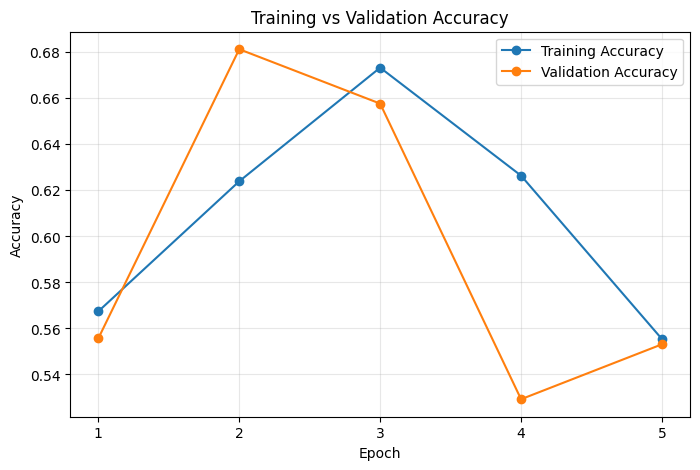

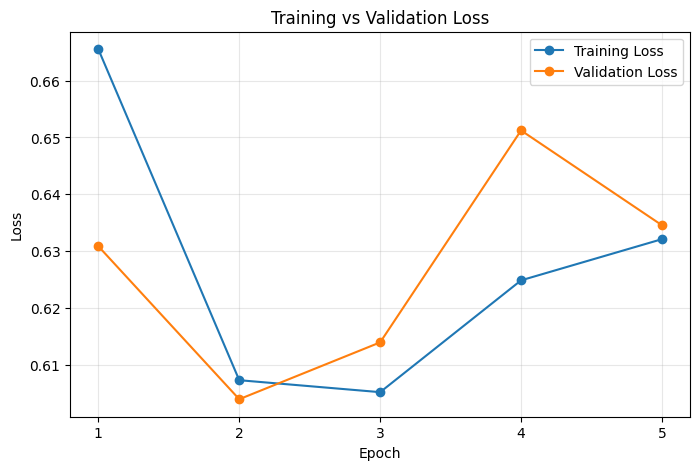

In [9]:
epochs = range(1, len(history.history['accuracy']) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['accuracy'], marker='o', label='Training Accuracy')
plt.plot(epochs, history.history['val_accuracy'], marker='o', label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['loss'], marker='o', label='Training Loss')
plt.plot(epochs, history.history['val_loss'], marker='o', label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

GRU comparison

In [10]:
from tensorflow.keras.layers import GRU
gru_model = Sequential([
     tf.keras.Input(shape=(50,)),
     Embedding(5000, 32),
     GRU(32),
     Dense(1, activation='sigmoid')
 ])
gru_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
gru_history = gru_model.fit(X_train_pad, y_train, epochs=5, validation_split=0.2, batch_size=32)
gru_loss, gru_accuracy = gru_model.evaluate(X_test_pad, y_test, verbose=0)
print(f'LSTM test accuracy: {test_accuracy:.2%}')
print(f'GRU test accuracy: {gru_accuracy:.2%}')

Epoch 1/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.5611 - loss: 0.6859 - val_accuracy: 0.5547 - val_loss: 0.6872
Epoch 2/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.5626 - loss: 0.6856 - val_accuracy: 0.5547 - val_loss: 0.6871
Epoch 3/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.5626 - loss: 0.6855 - val_accuracy: 0.5547 - val_loss: 0.6871
Epoch 4/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.5626 - loss: 0.6855 - val_accuracy: 0.5547 - val_loss: 0.6871
Epoch 5/5
535/535 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.5626 - loss: 0.6855 - val_accuracy: 0.5547 - val_loss: 0.6871
LSTM test accuracy: 54.47%
GRU test accuracy: 56.10%


**Forget gate explanation**

The forget gate allows an LSTM to decide which information from its previous cell state should be kept or discarded. Unlike a plain RNN, this helps the LSTM preserve useful information over longer sequences and reduces the vanishing-gradient problem.